In [1]:
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
insurance_data = pd.read_csv("insurance.csv")

X= insurance_data.drop(columns = ["charges"])
y = insurance_data["charges"]

X = pd.get_dummies(X, columns= ["region"], drop_first = True, dtype = int)

X["sex"] = X["sex"].map({"female" :1 , "male":0})
X["smoker"] = X["smoker"].map({"yes":1, "no":0})

X["age_smoker"] = X["age"]*X["smoker"]
X["bmi_smoker"] = X["bmi"]*X["smoker"]

X_train, X_test, y_train, y_test = train_test_split(X,y , test_size = 0.2, random_state = 42)

c:\Users\aniru\anaconda3\envs\qgss2024\Lib\site-packages\sklearn\base.py:1336: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
c:\Users\aniru\anaconda3\envs\qgss2024\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
c:\Users\aniru\anaconda3\envs\qgss2024\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.281e+10, tolerance: 1.544e+07
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
 

<Axes: >

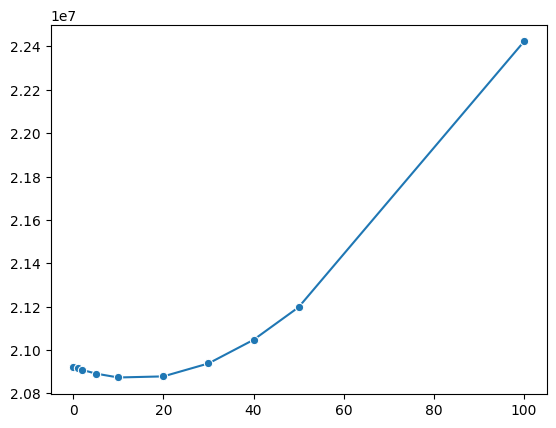

In [4]:
import seaborn as sns

alphas = [ 0.001,0,1,1,2,5,10,20,30,40,50,100]
mses =[]

for a in alphas:
    lasso_model = Lasso(alpha = a)
    lasso_model.fit(X_train, y_train)

    y_pred = lasso_model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)

    mses.append(mse)


sns.lineplot(x = alphas, y= mses, marker = "o")


In [6]:
from sklearn.linear_model import LassoCV

a = [0.001,0.1,1,2,5,10,20,30,40,50,100]

lasso_cv_model = LassoCV(
    alphas = a, cv = 5, max_iter = 1000, random_state = 42
)

lasso_cv_model.fit(X_train, y_train)

y_pred = lasso_cv_model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2= r2_score(y_test,y_pred)

print("best alpha :", lasso_cv_model.alpha_)
print("mse = ", mse)
print("s2 = ", r2)

best alpha : 0.001
mse =  20922599.871035974
s2 =  0.8652317499151698
